# R1 — Pruebas con Qwen2.5-VL-3B (modelo base, sin LoRA)

**Por qué Qwen y no LocateAnything:** la T4 de Colab (compute 7.5) queda fuera de lo que soporta LocateAnything. Qwen2.5-VL-3B sí corre en una T4 y además **acepta video**, así que el supervisor puede ver el clip completo y no solo frames sueltos.

**Qué vamos a medir antes de pensar en el LoRA:**

| Prueba | Pregunta |
|---|---|
| 1. Describir un frame | ¿El modelo carga y responde con sentido en la T4? |
| 2. Ubicar objetos (cajas) | ¿Localiza vehículos y personas en vista tipo C5? (lo que iba a hacer LocateAnything) |
| 3. Juzgar un clip | ¿Reconoce un incidente viendo el video completo? |
| 4. Todas las muestras | ¿Cuánto tarda por clip y qué tan seguido acierta *sin entrenar*? |

Ese último número es la **línea base**: el LoRA tiene que superarla, y esa comparación es lo que más pesa en la calificación.

**Antes de empezar:** en Colab, *Entorno de ejecución → Cambiar tipo de entorno → T4 GPU*.

## 0. Instalación

Si Colab pide **reiniciar la sesión** después de instalar, reinicia y continúa desde la celda siguiente (no vuelvas a instalar).

In [ ]:
%pip install -q "transformers>=4.51" accelerate "qwen-vl-utils[decord]" bitsandbytes huggingface_hub opencv-python-headless pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 43.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 64.7 MB/s eta 0:00:00


In [ ]:
import os, re, json, time, glob, zipfile, random
import torch
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

assert torch.cuda.is_available(), "No hay GPU: Entorno de ejecución → Cambiar tipo de entorno → T4 GPU"
p = torch.cuda.get_device_properties(0)
print(f"GPU: {p.name} · {p.total_memory/1e9:.1f} GB · compute {p.major}.{p.minor}")

DIR_DATOS = os.environ.get("ROADVISION_DATA", "/content/datos_roadvision")
DIR_MUESTRAS = os.path.join(DIR_DATOS, "muestras")
DIR_FRAMES = os.path.join(DIR_DATOS, "frames")
DIR_RESULTADOS = os.path.join(DIR_DATOS, "resultados_qwen")
for d in (DIR_MUESTRAS, DIR_FRAMES, DIR_RESULTADOS):
    os.makedirs(d, exist_ok=True)

EXT_VIDEO = (".mp4", ".mov", ".avi", ".mkv", ".webm", ".m4v")
print("Datos en:", DIR_DATOS)

GPU: Tesla T4 · 15.6 GB · compute 7.5
Datos en: /content/datos_roadvision


### (Opcional) Guardar resultados en Google Drive

El disco de Colab se borra al cerrar la sesión. Pon `USAR_DRIVE = True` para guardar muestras y resultados en tu Drive.

In [ ]:
USAR_DRIVE = False

if USAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DIR_DATOS = "/content/drive/MyDrive/roadvision"
    DIR_MUESTRAS = os.path.join(DIR_DATOS, "muestras")
    DIR_FRAMES = os.path.join(DIR_DATOS, "frames")
    DIR_RESULTADOS = os.path.join(DIR_DATOS, "resultados_qwen")
    for d in (DIR_MUESTRAS, DIR_FRAMES, DIR_RESULTADOS):
        os.makedirs(d, exist_ok=True)
    print("Usando Drive:", DIR_DATOS)

## 1. Conseguir muestras (si no hay)

Si ya corriste R0 en esta misma sesión, aquí ya hay videos. Si no, baja unos cuantos: de **VRU-Accident** (sacándolos del ZIP sin bajarlo completo) y de **Accident-Bench `land_space/`** (videos sueltos).

In [ ]:
N_VRU = 5
N_ACCIDENT_BENCH = 5
MAX_MB = 60


def videos_en_disco():
    rutas = []
    for raiz, _d, archivos in os.walk(DIR_MUESTRAS):
        if ".cache" in raiz.split(os.sep):
            continue
        rutas += [os.path.join(raiz, f) for f in sorted(archivos) if f.lower().endswith(EXT_VIDEO)]
    return rutas


def espaciada(lista, n):
    if not lista or n <= 0:
        return []
    paso = max(1, len(lista) // n)
    return lista[::paso][:n]


if len(videos_en_disco()) < 3:
    from huggingface_hub import HfApi, HfFileSystem, hf_hub_download
    api, fs = HfApi(), HfFileSystem()

    # VRU-Accident: extraer del ZIP remoto solo los miembros elegidos
    with fs.open("datasets/kyh9191/VRU-Accident/VRU_videos.zip", "rb", block_size=1024 * 1024) as fh:
        with zipfile.ZipFile(fh) as z:
            miembros = sorted(i.filename for i in z.infolist()
                              if i.filename.lower().endswith(EXT_VIDEO) and i.file_size < MAX_MB * 1e6)
            for m in espaciada(miembros, N_VRU):
                z.extract(m, path=os.path.join(DIR_MUESTRAS, "kyh9191__VRU-Accident"))

    # Accident-Bench: solo land_space/
    info = api.dataset_info("Accident-Bench/Dataset", files_metadata=True)
    sueltos = sorted(s.rfilename for s in info.siblings
                     if s.rfilename.startswith("land_space/") and s.rfilename.lower().endswith(EXT_VIDEO)
                     and (s.size or 0) < MAX_MB * 1e6)
    for f in espaciada(sueltos, N_ACCIDENT_BENCH):
        hf_hub_download("Accident-Bench/Dataset", f, repo_type="dataset",
                        local_dir=os.path.join(DIR_MUESTRAS, "Accident-Bench__Dataset"))

VIDEOS = videos_en_disco()
print(f"{len(VIDEOS)} videos disponibles")
for v in VIDEOS[:12]:
    print(" ", os.path.relpath(v, DIR_MUESTRAS))

land_space/long/videos/-GpvLzopst8.mp4: reconstructing file:   0%|          |  0.00B / 3.83MB            

land_space/long/videos/-GpvLzopst8.mp4: downloading bytes:           |  0.00B            

land_space/short/videos/000161.mp4: reconstructing file:   0%|          |  0.00B /  693kB            

land_space/short/videos/000161.mp4: downloading bytes:           |  0.00B            

land_space/short/videos/000496.mp4: reconstructing file:   0%|          |  0.00B /  530kB            

land_space/short/videos/000496.mp4: downloading bytes:           |  0.00B            

land_space/short/videos/000831.mp4: reconstructing file:   0%|          |  0.00B /  984kB            

land_space/short/videos/000831.mp4: downloading bytes:           |  0.00B            

land_space/short/videos/001166.mp4: reconstructing file:   0%|          |  0.00B /  746kB            

land_space/short/videos/001166.mp4: downloading bytes:           |  0.00B            

10 videos disponibles
  kyh9191__VRU-Accident/VRU_videos/MANUAL_DATA/VRU_270.mp4
  kyh9191__VRU-Accident/VRU_videos/DoTA/VRU_90.mp4
  kyh9191__VRU-Accident/VRU_videos/CAP_DATA/VRU_1.mp4
  kyh9191__VRU-Accident/VRU_videos/CAP_DATA/VRU_28.mp4
  kyh9191__VRU-Accident/VRU_videos/DADA_2000/VRU_200.mp4
  Accident-Bench__Dataset/land_space/short/videos/000161.mp4
  Accident-Bench__Dataset/land_space/short/videos/000496.mp4
  Accident-Bench__Dataset/land_space/short/videos/000831.mp4
  Accident-Bench__Dataset/land_space/short/videos/001166.mp4
  Accident-Bench__Dataset/land_space/long/videos/-GpvLzopst8.mp4


In [ ]:
def frame_central(ruta_video):
    """Devuelve (ruta_jpg, imagen_BGR) del frame central del video."""
    cap = cv2.VideoCapture(ruta_video)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.set(cv2.CAP_PROP_POS_FRAMES, max(0, total // 2))
    ok, img = cap.read()
    cap.release()
    if not ok:
        return None, None
    rel = os.path.splitext(os.path.relpath(ruta_video, DIR_MUESTRAS))[0]
    salida = os.path.join(DIR_FRAMES, rel + "_central.jpg")
    os.makedirs(os.path.dirname(salida), exist_ok=True)
    cv2.imwrite(salida, img)
    return salida, img


FRAMES = [f for f, _ in (frame_central(v) for v in VIDEOS) if f]
print(f"{len(FRAMES)} frames centrales listos")

10 frames centrales listos


## 2. Cargar Qwen2.5-VL-3B en la T4

- La T4 **no tiene bf16**, por eso se carga en **fp16** (~7.5 GB de 15.6).
- Si en la Prueba 1 la respuesta sale como basura (`!!!!`, símbolos repetidos o vacía), cambia a `MODO = "4bit"` y vuelve a correr desde aquí. Es más lento, pero estable.
- Licencia: la versión 3B usa la licencia de investigación de Qwen (no comercial). Para la escuela está bien.

In [ ]:
MODO = "fp16"          # "fp16" o "4bit"
MODELO_ID = "Qwen/Qwen2.5-VL-3B-Instruct"

import transformers
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor

# transformers >= 4.56 usa "dtype"; versiones anteriores, "torch_dtype"
_v = tuple(int(x) for x in re.findall(r"\d+", transformers.__version__)[:2])
DTYPE_KW = "dtype" if _v >= (4, 56) else "torch_dtype"
print("transformers", transformers.__version__)

t0 = time.time()
if MODO == "4bit":
    from transformers import BitsAndBytesConfig
    cuant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                               bnb_4bit_compute_dtype=torch.float16)
    modelo = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        MODELO_ID, quantization_config=cuant, device_map="auto", attn_implementation="sdpa")
else:
    modelo = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        MODELO_ID, **{DTYPE_KW: torch.float16}, device_map="auto", attn_implementation="sdpa")
modelo.eval()

# max_pixels limita la resolución que ve el modelo: menos píxeles = menos memoria y más rápido.
procesador = AutoProcessor.from_pretrained(MODELO_ID, min_pixels=256 * 28 * 28, max_pixels=1024 * 28 * 28)

print(f"Cargado en {time.time() - t0:.0f} s · VRAM usada: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

transformers 5.20.1


config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

... (4 outputs left out)

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Cargado en 101 s · VRAM usada: 7.5 GB


In [ ]:
from qwen_vl_utils import process_vision_info


def preguntar(contenido, max_new_tokens=256):
    """Envía un mensaje (lista de partes image/video/text) y devuelve (texto, segundos, entradas)."""
    mensajes = [{"role": "user", "content": contenido}]
    texto = procesador.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True)
    try:
        imgs, vids, video_kwargs = process_vision_info(mensajes, return_video_kwargs=True)
    except TypeError:  # versiones viejas de qwen-vl-utils
        imgs, vids = process_vision_info(mensajes)
        video_kwargs = {}

    # qwen-vl-utils devuelve fps como lista ([] si no hay video), pero las versiones
    # nuevas de transformers exigen un número. Solo se pasa cuando hay video.
    extra = {}
    if vids:
        fps = (video_kwargs or {}).get("fps")
        if isinstance(fps, (list, tuple)):
            fps = fps[0] if fps else None
        if fps is not None:
            extra["fps"] = float(fps)

    entradas = procesador(text=[texto], images=imgs or None, videos=vids or None, padding=True,
                          return_tensors="pt", **extra).to(modelo.device)
    torch.cuda.synchronize()
    t0 = time.time()
    with torch.no_grad():
        salida = modelo.generate(**entradas, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    segundos = time.time() - t0
    nuevos = salida[:, entradas["input_ids"].shape[1]:]
    respuesta = procesador.batch_decode(nuevos, skip_special_tokens=True)[0].strip()
    return respuesta, segundos, entradas


def parece_basura(texto):
    t = texto.strip()
    return len(t) == 0 or len(set(t)) <= 3 or t.count("!") > len(t) * 0.5


def extraer_json(texto):
    """Saca el primer objeto o lista JSON de la respuesta (tolera ```json y texto extra)."""
    t = re.sub(r"```(?:json)?", "", texto)
    inicio = min([i for i in (t.find("{"), t.find("[")) if i >= 0], default=-1)
    if inicio < 0:
        return None
    for fin in range(len(t), inicio, -1):
        try:
            return json.loads(t[inicio:fin])
        except json.JSONDecodeError:
            continue
    return None

## Prueba 1 — Describir un frame

Primero hay que comprobar que el modelo responde con sentido en la T4.

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


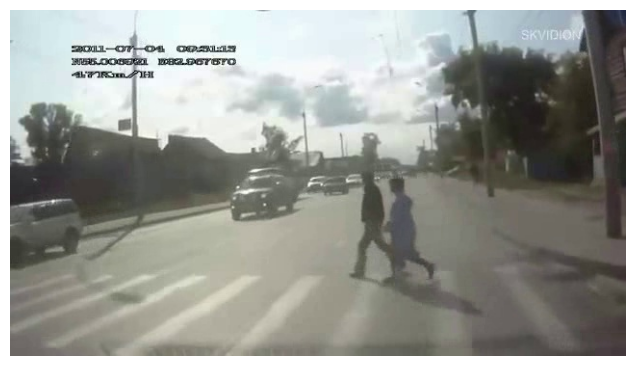

La cámara parece estar montada en un vehículo, ya que la imagen está ligeramente inclinada y se puede ver el movimiento del vehículo que la toma.

⏱ 2.1 s


In [ ]:
frame = FRAMES[0]
resp, seg, _ = preguntar([
    {"type": "image", "image": frame},
    {"type": "text", "text": "Describe esta escena de tráfico en 2 oraciones en español. "
                             "¿La cámara parece fija (tipo vigilancia) o montada en un vehículo?"},
])
plt.figure(figsize=(8, 4.5)); plt.imshow(cv2.cvtColor(cv2.imread(frame), cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()
print(resp)
print(f"\n⏱ {seg:.1f} s")
if parece_basura(resp):
    print("\n⚠️  La respuesta parece basura: cambia MODO = '4bit' en la celda de carga y vuelve a correr.")

## Prueba 2 — Ubicar objetos con cajas (lo que iba a hacer LocateAnything)

Qwen2.5-VL devuelve coordenadas en **píxeles de la imagen redimensionada** que vio el modelo, no de la original. La función las reescala antes de dibujarlas.

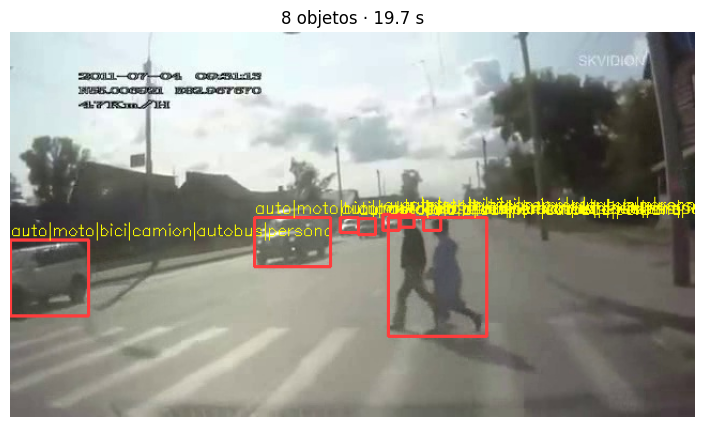

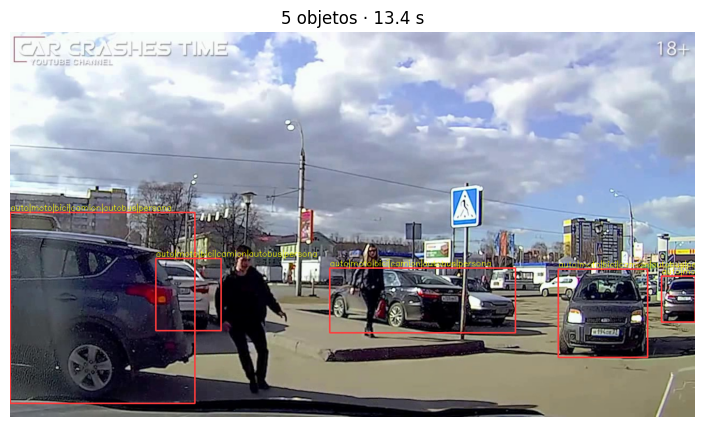

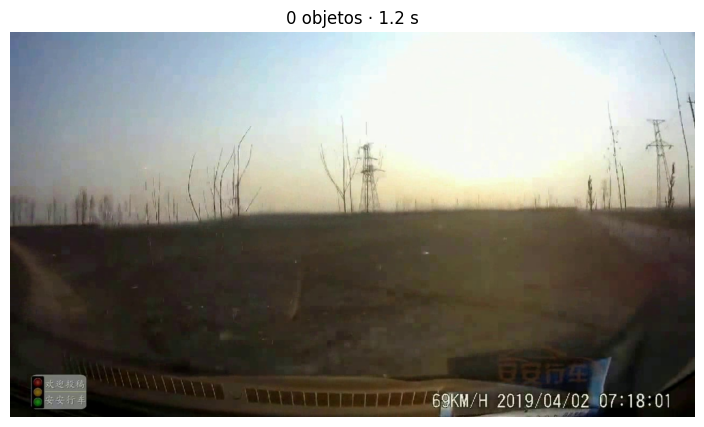

Respuesta sin JSON válido: []


In [ ]:
PROMPT_CAJAS = ('Detecta todos los vehículos, motocicletas, bicicletas y personas en la imagen. '
                'Responde SOLO con una lista JSON: '
                '[{"bbox_2d": [x1, y1, x2, y2], "label": "auto|moto|bici|camion|autobus|persona"}]')


def detectar_cajas(ruta_img):
    resp, seg, entradas = preguntar([{"type": "image", "image": ruta_img},
                                     {"type": "text", "text": PROMPT_CAJAS}], max_new_tokens=512)
    img = cv2.imread(ruta_img)
    alto, ancho = img.shape[:2]
    _, gh, gw = entradas["image_grid_thw"][0].tolist()
    esc_x, esc_y = ancho / (gw * 14), alto / (gh * 14)   # cada celda de la rejilla mide 14 px
    cajas = []
    for o in (extraer_json(resp) or []):
        if isinstance(o, dict) and len(o.get("bbox_2d", [])) == 4:
            x1, y1, x2, y2 = o["bbox_2d"]
            cajas.append({"label": o.get("label", "?"),
                          "x1": int(x1 * esc_x), "y1": int(y1 * esc_y),
                          "x2": int(x2 * esc_x), "y2": int(y2 * esc_y)})
    return cajas, seg, resp


def dibujar(ruta_img, cajas, titulo=""):
    img = cv2.cvtColor(cv2.imread(ruta_img), cv2.COLOR_BGR2RGB)
    for c in cajas:
        cv2.rectangle(img, (c["x1"], c["y1"]), (c["x2"], c["y2"]), (255, 60, 60), 2)
        cv2.putText(img, c["label"], (c["x1"], max(12, c["y1"] - 4)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 0), 1)
    plt.figure(figsize=(9, 5)); plt.imshow(img); plt.title(titulo); plt.axis("off"); plt.show()


for f in FRAMES[:3]:
    cajas, seg, crudo = detectar_cajas(f)
    dibujar(f, cajas, f"{len(cajas)} objetos · {seg:.1f} s")
    if not cajas:
        print("Respuesta sin JSON válido:", crudo[:300])

## Prueba 3 — Juzgar un clip completo

Aquí está la ventaja frente a LocateAnything: el modelo ve el **movimiento**. Para que quepa en la T4, el video se muestrea a `FPS_VIDEO` y se limita su resolución con `MAX_PIXELES_VIDEO`.

In [ ]:
FPS_VIDEO = 2.0
MAX_PIXELES_VIDEO = 360 * 420

PROMPT_INCIDENTE = (
    "Eres un operador de un centro de monitoreo de tráfico (C5). Mira el video y responde SOLO con JSON:\n"
    '{"incidente": true|false, '
    '"tipo": "choque_vehiculos|atropello|moto_caida|vehiculo_detenido|ninguno|otro", '
    '"segundo_aprox": número o null, '
    '"camara_fija": true|false, '
    '"descripcion": "una oración en español"}'
)


def juzgar_clip(ruta_video):
    resp, seg, entradas = preguntar([
        {"type": "video", "video": ruta_video, "fps": FPS_VIDEO, "max_pixels": MAX_PIXELES_VIDEO},
        {"type": "text", "text": PROMPT_INCIDENTE},
    ], max_new_tokens=200)
    datos = extraer_json(resp)
    if not isinstance(datos, dict):
        datos = {"incidente": None, "tipo": "sin_json", "descripcion": resp[:200]}
    datos["segundos"] = round(seg, 2)
    datos["tokens_entrada"] = int(entradas["input_ids"].shape[1])
    return datos


r = juzgar_clip(VIDEOS[0])
print(os.path.relpath(VIDEOS[0], DIR_MUESTRAS))
print(json.dumps(r, indent=2, ensure_ascii=False))

qwen-vl-utils using torchcodec to read video.
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/video_processing_qwen2_vl.py:156: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
[transformers] Qwen2VL video processing does not apply the per-frame pixel cap the reference implementation (qwen-vl-utils) applies, so some videos cost far more tokens than they would there. In v5.22 the capped behavior will become the default and `cap_pixels_per_frame` will be removed. Pass `cap_pixels_per_frame=True` to adopt the reference behavior now, or `False` to keep the current behavior and silence this warning.


kyh9191__VRU-Accident/VRU_videos/MANUAL_DATA/VRU_270.mp4
{
  "incidente": null,
  "tipo": "sin_json",
  "descripcion": "```json\n{\n  \"incidente\": true,\n  \"tipo\": \"atropello\",\n  \"segundo_aprox\": 2011-07-04 09:51:13,\n  \"camara_fija\": false,\n  \"descripcion\": \"una oración en español\"\n}\n```",
  "segundos": 7.71,
  "tokens_entrada": 2759
}


## Prueba 4 — Todas las muestras: línea base sin LoRA

`etiqueta_real` es lo que **sabemos** del video por su origen. Todo lo de VRU-Accident muestra atropellos, así que se marca como incidente; lo de Accident-Bench se deja como "desconocido" porque mezcla escenas. Cuando tengan ACCIDENT de Kaggle, sus etiquetas reemplazan esta columna y la evaluación ya es formal.

In [ ]:
def etiqueta_por_origen(ruta):
    rel = os.path.relpath(ruta, DIR_MUESTRAS).lower()
    if "vru-accident" in rel:
        return True
    return None   # desconocido


filas = []
for i, v in enumerate(VIDEOS, 1):
    try:
        r = juzgar_clip(v)
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache()
        r = {"incidente": None, "tipo": "sin_memoria", "descripcion": "Baja MAX_PIXELES_VIDEO o FPS_VIDEO"}
    r.update({"archivo": os.path.relpath(v, DIR_MUESTRAS), "etiqueta_real": etiqueta_por_origen(v)})
    filas.append(r)
    print(f"[{i}/{len(VIDEOS)}] {r['archivo'][:60]} → {r.get('incidente')} · {r.get('tipo')} · {r.get('segundos')} s")

resultados = pd.DataFrame(filas)
columnas = ["archivo", "etiqueta_real", "incidente", "tipo", "camara_fija", "segundo_aprox",
            "segundos", "tokens_entrada", "descripcion"]
resultados = resultados[[c for c in columnas if c in resultados.columns]]
salida_csv = os.path.join(DIR_RESULTADOS, f"linea_base_qwen_{time.strftime('%Y%m%d_%H%M')}.csv")
resultados.to_csv(salida_csv, index=False)
display(resultados)
print("Guardado en", salida_csv)

[1/10] kyh9191__VRU-Accident/VRU_videos/MANUAL_DATA/VRU_270.mp4 → None · sin_json · 7.67 s
[2/10] kyh9191__VRU-Accident/VRU_videos/DoTA/VRU_90.mp4 → True · atropello · 4.48 s
[3/10] kyh9191__VRU-Accident/VRU_videos/CAP_DATA/VRU_1.mp4 → True · choque_vehiculos · 4.04 s
[4/10] kyh9191__VRU-Accident/VRU_videos/CAP_DATA/VRU_28.mp4 → None · sin_json · 9.96 s
[5/10] kyh9191__VRU-Accident/VRU_videos/DADA_2000/VRU_200.mp4 → None · sin_json · 12.45 s
[6/10] Accident-Bench__Dataset/land_space/short/videos/000161.mp4 → True · choque_vehiculos · 4.57 s
[7/10] Accident-Bench__Dataset/land_space/short/videos/000496.mp4 → True · choque_vehiculos · 4.16 s
[8/10] Accident-Bench__Dataset/land_space/short/videos/000831.mp4 → True · choque_vehiculos · 4.57 s
[9/10] Accident-Bench__Dataset/land_space/short/videos/001166.mp4 → None · sin_json · 4.62 s
[10/10] Accident-Bench__Dataset/land_space/long/videos/-GpvLzopst8.m → None · sin_memoria · None s


,archivo,etiqueta_real,incidente,tipo,camara_fija,segundo_aprox,segundos,tokens_entrada,descripcion
0,kyh9191__VRU-Accident/VRU_videos/MANUAL_DATA/V...,True,None,sin_json,NaN,NaN,7.67,2759.0,"```json\n{\n ""incidente"": true,\n ""tipo"": ""a..."
1,kyh9191__VRU-Accident/VRU_videos/DoTA/VRU_90.mp4,True,True,atropello,False,10.0,4.48,1703.0,una oración en español
2,kyh9191__VRU-Accident/VRU_videos/CAP_DATA/VRU_...,True,True,choque_vehiculos,False,718.0,4.04,1175.0,un choque entre dos vehículos
3,kyh9191__VRU-Accident/VRU_videos/CAP_DATA/VRU_...,True,None,sin_json,NaN,NaN,9.96,3815.0,"```json\n{\n ""incidente"": true,\n ""tipo"": ""c..."
4,kyh9191__VRU-Accident/VRU_videos/DADA_2000/VRU...,True,None,sin_json,NaN,NaN,12.45,4279.0,"```json\n{\n ""incidente"": true,\n ""tipo"": ""a..."
5,Accident-Bench__Dataset/land_space/short/video...,None,True,choque_vehiculos,False,15.0,4.57,1439.0,un coche se detiene en la carretera
6,Accident-Bench__Dataset/land_space/short/video...,None,True,choque_vehiculos,False,NaN,4.16,1439.0,una oración en español
7,Accident-Bench__Dataset/land_space/short/video...,None,True,choque_vehiculos,False,9.0,4.57,1439.0,un choque entre vehículos en una calle residen...
8,Accident-Bench__Dataset/land_space/short/video...,None,None,sin_json,NaN,NaN,4.62,1439.0,"```json\n{\n ""incidente"": true,\n ""tipo"": ""c..."
9,Accident-Bench__Dataset/land_space/long/videos...,None,None,sin_memoria,NaN,NaN,NaN,NaN,Baja MAX_PIXELES_VIDEO o FPS_VIDEO


Guardado en /content/datos_roadvision/resultados_qwen/linea_base_qwen_20261022_1928.csv


In [ ]:
conocidos = resultados[resultados["etiqueta_real"].notna()]
if len(conocidos):
    aciertos = (conocidos["incidente"] == conocidos["etiqueta_real"]).mean()
    print(f"Aciertos en videos con etiqueta conocida: {aciertos:.0%} ({len(conocidos)} videos)")
print(f"Respuestas sin JSON válido: {(resultados['tipo'] == 'sin_json').sum()} de {len(resultados)}")
print(f"Cámara fija según el modelo: {resultados.get('camara_fija', pd.Series()).value_counts(dropna=False).to_dict()}")

lat = resultados["segundos"].dropna()
if len(lat):
    print(f"\nLatencia por clip: mediana {lat.median():.1f} s · máx {lat.max():.1f} s")
    # Presupuesto de tiempo real con el número medido (misma lógica que R0.8)
    N_CAMARAS, ALERTAS_POR_HORA = 100, 2
    clips_por_s = N_CAMARAS * ALERTAS_POR_HORA / 3600
    print(f"Con {N_CAMARAS} cámaras y {ALERTAS_POR_HORA} alertas/cámara/hora: "
          f"{clips_por_s:.3f} clips/s → {clips_por_s * lat.median():.2f} T4 ocupadas en promedio")

Aciertos en videos con etiqueta conocida: 40% (5 videos)
Respuestas sin JSON válido: 4 de 10
Cámara fija según el modelo: {nan: 5, False: 5}

Latencia por clip: mediana 4.6 s · máx 12.4 s
Con 100 cámaras y 2 alertas/cámara/hora: 0.056 clips/s → 0.25 T4 ocupadas en promedio


## Cómo leer los resultados

- **Prueba 1 con sentido** → el modelo funciona en la T4; ya hay supervisor.
- **Prueba 2:** si las cajas caen bien sobre los objetos, Qwen cubre lo que iba a hacer LocateAnything. Si no, el detector del paso 1 (YOLO) se encarga de las cajas y Qwen solo juzga.
- **Prueba 4:** los aciertos y las fallas *sin entrenar* son la **línea base**. Anoten dónde se equivoca (de noche, con lluvia, choques leves, cámara lejana): esos casos son los que el LoRA debe mejorar.
- **Ojo:** con solo videos con incidente no se puede medir falsas alarmas. Para la evaluación formal hacen falta clips **sin** incidente, y ACCIDENT trae ambos.
- **`camara_fija`** también sirve para filtrar: los videos donde el modelo dice "montada en vehículo" son candidatos a descartar por perspectiva.

**Siguiente paso (R2):** convertir las etiquetas de ACCIDENT en pares pregunta→JSON y entrenar el LoRA con QLoRA en la T4, para luego comparar contra esta línea base con los mismos clips de prueba.